In [ ]:
import numpy as np
from numpy.linalg import svd

X = np.array([[3, 1],
              [1, 3],
              [4, 2]])

print('3 × 2 matrix X:')
print(X)

# Center the data
CX = X - np.mean(X, axis=0)

# Singular Value Decomposition of centered data
U, Sigma, VT = svd(CX, full_matrices=False)

V = VT.T

print('\nChecks')

print('\n1. U.T @ U = I_2, but U @ U.T != I_3:')
print(U.T @ U)
print(U @ U.T)

print('\n2. V.T @ V = I_2 and V @ V.T = I_2:')
print(V.T @ V)
print(V @ V.T)

print('\nPrincipal directions of X (column-wise):')
print(V)

# Principal components / scores
PC = U * Sigma

print('\nPrincipal components of X (column-wise):')
print(PC)

# PCA variances
variance = Sigma**2 / (CX.shape[0] - 1)

print('\nVariance of each principal component:')
print(variance)

print('\nExplained variance ratio:')
print(variance / np.sum(variance))

print('\nCumulative explained variance ratio:')
print(np.cumsum(variance) / np.sum(variance))


3 × 2 matrix X:
[[3 1]
 [1 3]
 [4 2]]

Checks

1. U.T @ U = I_2, but U @ U.T != I_3:
[[1.00000000e+00 1.17515717e-16]
 [1.17515717e-16 1.00000000e+00]]
[[ 0.66666667 -0.33333333 -0.33333333]
 [-0.33333333  0.66666667 -0.33333333]
 [-0.33333333 -0.33333333  0.66666667]]

2. V.T @ V = I_2 and V @ V.T = I_2:
[[1.0000000e+00 2.7595702e-17]
 [2.7595702e-17 1.0000000e+00]]
[[1.0000000e+00 2.7595702e-17]
 [2.7595702e-17 1.0000000e+00]]

Principal directions of X (column-wise):
[[-0.8816746   0.47185793]
 [ 0.47185793  0.8816746 ]]

Principal components of X (column-wise):
[[-0.76574946 -0.72438862]
 [ 1.94131559  0.09524472]
 [-1.17556613  0.6291439 ]]

Variance of each principal component:
[2.86851709 0.46481624]

Explained variance ratio:
[0.86055513 0.13944487]

Cumulative explained variance ratio:
[0.86055513 1.        ]


In [ ]:
import sklearn.datasets
import pandas as pd

# Load wine dataset
data = sklearn.datasets.load_wine()
X = data.data
y = data.target
target_names = data.target_names

# Convert to DataDrame to easily inspect column, names, types and rows
df = pd.DataFrame(X, columns=data.feature_names)

# Print column names
print('Column names:')
print(df.columns)

# Print column types
print('\nColumn Types:')
print(df.dtypes)

# Display the first 5 rows
print('\n First 5 rows:')
print(df.head())

# Examine occurences of each class in y
print('\nCounts of each class in y:')
target_ids = {}
for i, target_name in enumerate(target_names):
  b = (y == i)
  print(f'{target_name}:{sum(b)}')
  target_ids[target_name] = b

print('\n Total length:')
print(y.shape[-1])

Column names:
Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline'],
      dtype='object')

Column Types:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
dtype: object

 First 5 rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13

In [ ]:
# Center the data
X /= np.std(X, axis=0)
CX = X - np.mean(X, axis=0)

# Perform PCA
U, Sigma, VT = svd(CX, full_matrices=False)
PC = U * Sigma

# PCA variances
variance = Sigma ** 2 / (CX.shape[0] - 1)
print('\nVariance of each principal component:')
print(variance)

print('\nExplained variance ratio:')
print(variance / np.sum(variance))

print('\nCumulative explained variance ratio:')
print(np.cumsum(variance) / np.sum(variance))


Variance of each principal component:
[4.73243698 2.51108093 1.45424187 0.92416587 0.85804868 0.64528221
 0.55414147 0.35046627 0.29051203 0.25232001 0.22706428 0.16972374
 0.10396199]

Explained variance ratio:
[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]

Cumulative explained variance ratio:
[0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


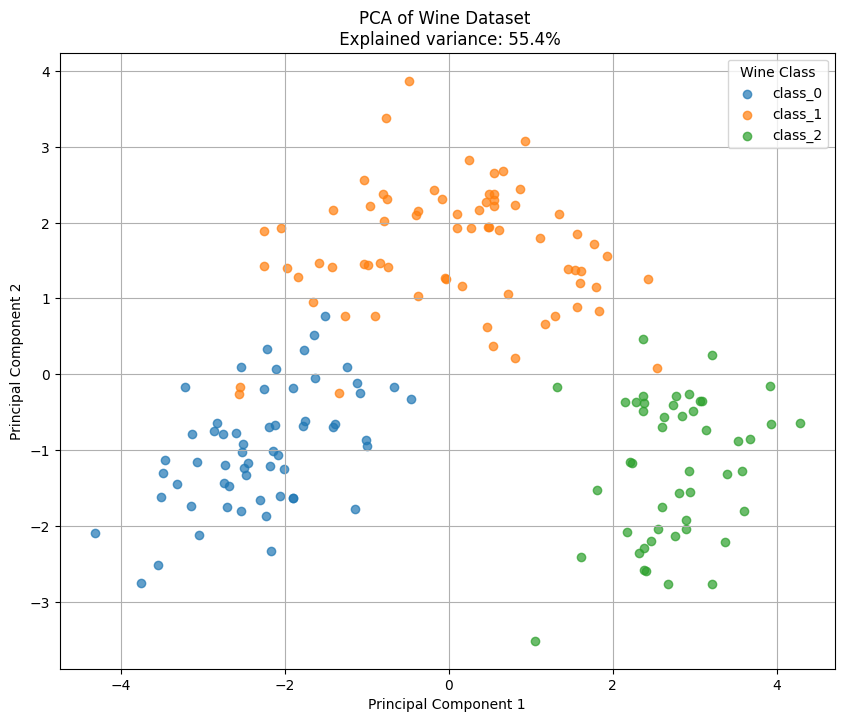

In [ ]:
import matplotlib.pyplot as plt

# Plot the PCA results with color coding wine class
plt.figure(figsize=(10, 8))
for target_name, target_id in target_ids.items():
  plt.scatter(PC[target_id, 0], PC[target_id, 1], label=target_name, alpha = 0.7)

explained = (variance[0] + variance[1])/sum(variance)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title(f'PCA of Wine Dataset \n Explained variance: {explained:.1%}')
plt.legend(title='Wine Class')
plt.grid(True)
plt.show()

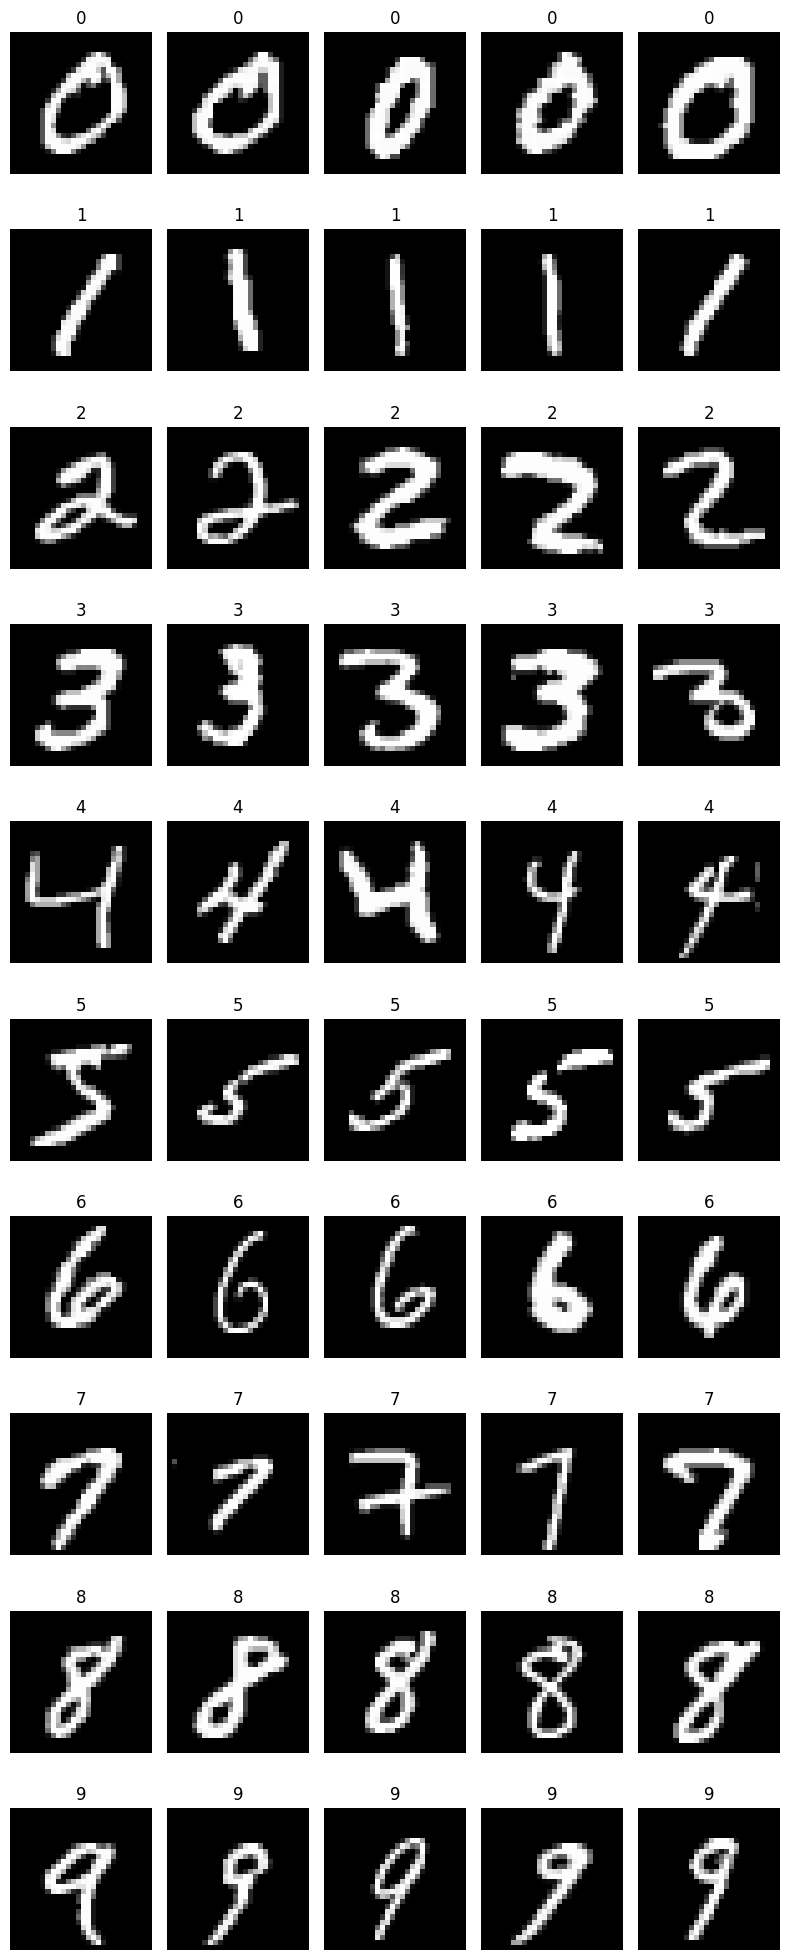

In [ ]:
import torch
import torchvision

# Reading MNIST Dataset
data = torchvision.datasets.MNIST(
    root='./data',
    download=True
)

X = data.data.numpy().astype(np.float64)
y = data.targets

# Printing example digits
counts = {digit: 0 for digit in range(10)}
printed = 0
fig, axes = plt.subplots(10, 5, figsize=(8, 20))

for x, label in zip(X, y):
  label = label.item()
  row, col = label, counts[label]

  if counts[label] < 5:
    axes[row, col].imshow(x, cmap='gray')
    axes[row, col].set_title(str(label))
    axes[row, col].axis('off')

    counts[label] += 1
    printed += 1

    if printed == 50:
      break


plt.tight_layout()
plt.show()

In [ ]:
# Center the data
X = X.reshape(X.shape[0], -1)
X /= 255.0
CX = X - np.mean(X, axis = 0)

# Flatten each 28 × 28 image into a 784-dimensional vector
# Perform PCA
U, Sigma, VT = svd(CX, full_matrices=False)
PC = U * Sigma

# PCA variances
variance = Sigma ** 2 / (CX.shape[0] - 1)
variance_ratio = variance/np.sum(variance)

print('\nVariance of the first 20 principal components:')
print(variance[:20])

print('\nExplained variance ratioof the first 20 principal components:')
print(variance_ratio[:20])

print('\nCumulative explained variance ratioof the first 20 principal components:')
print(np.cumsum(variance_ratio[:20]))



Variance of the first 20 principal components:
[5.11687301 3.74139084 3.25270845 2.8416207  2.56711774 2.27366339
 1.72515498 1.52056024 1.45630525 1.24275009 1.11208951 1.06664054
 0.90468083 0.89218122 0.83235305 0.78190032 0.69838687 0.67325581
 0.62599524 0.60776302]

Explained variance ratioof the first 20 principal components:
[0.09704664 0.07095924 0.06169089 0.05389419 0.04868797 0.04312231
 0.0327193  0.02883895 0.02762029 0.02357001 0.0210919  0.02022991
 0.01715818 0.01692111 0.01578641 0.01482953 0.01324561 0.01276897
 0.01187263 0.01152684]

Cumulative explained variance ratioof the first 20 principal components:
[0.09704664 0.16800588 0.22969677 0.28359097 0.33227894 0.37540125
 0.40812055 0.4369595  0.4645798  0.4881498  0.5092417  0.52947161
 0.54662979 0.56355091 0.57933732 0.59416685 0.60741246 0.62018143
 0.63205406 0.6435809 ]


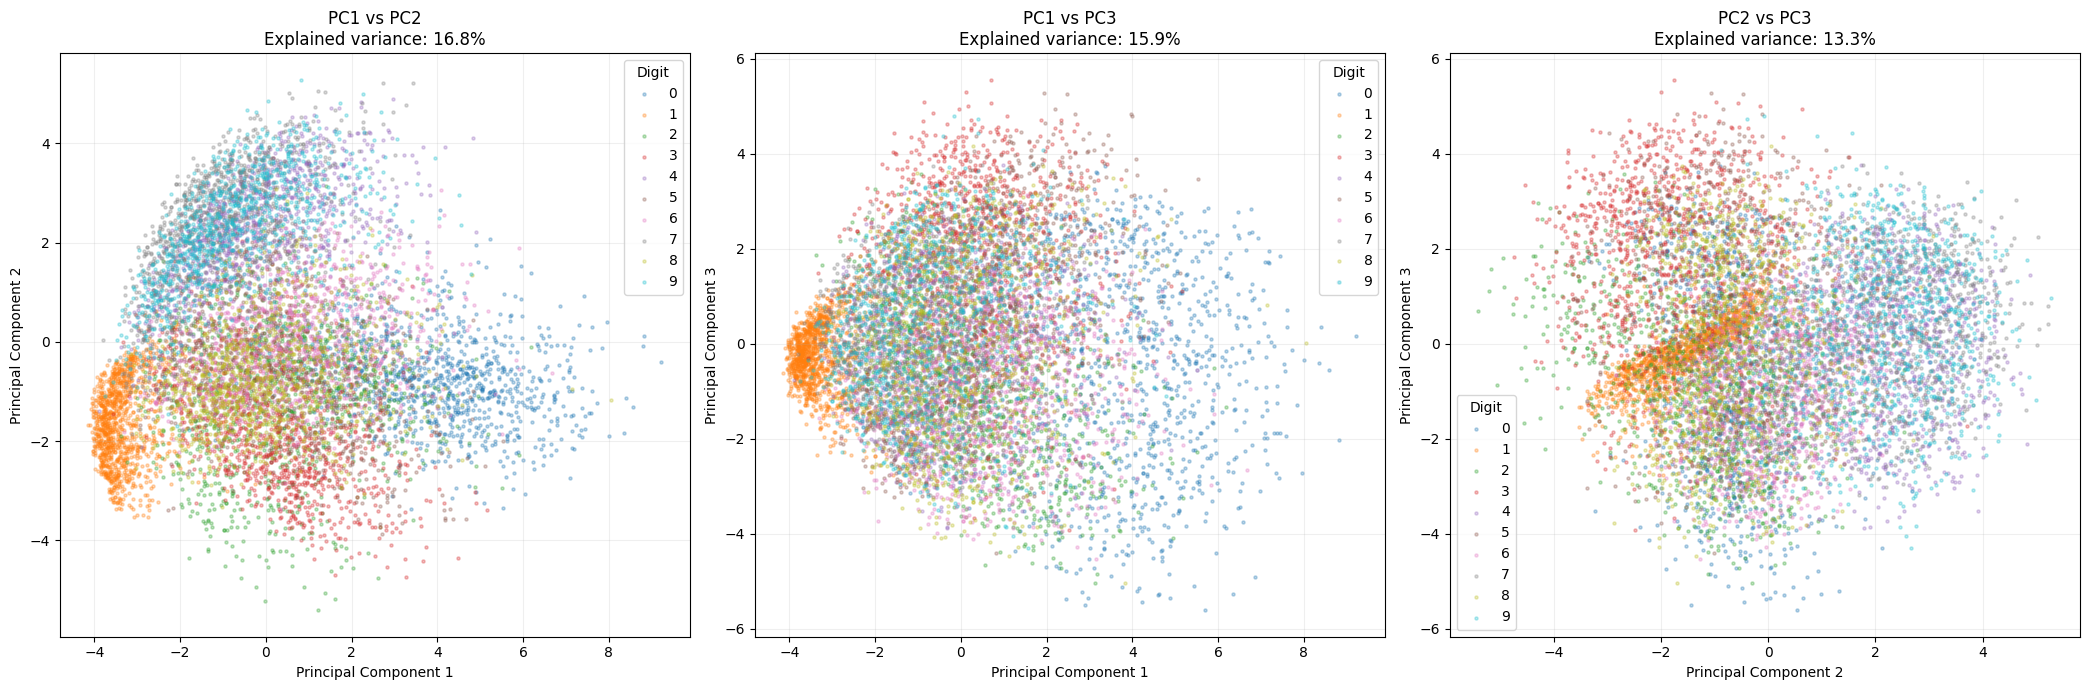

In [ ]:
torch.manual_seed(42)
idx = torch.randperm(len(y))[:10_000]
y_sample = y[idx]
PC_sample = PC[idx]

digit_ids = {str(digit): (y_sample == digit) for digit in range(10)}
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

for k, (i, j) in enumerate(((0, 1), (0, 2), (1, 2))):

  for digit, digit_id in digit_ids.items():
    axes[k].scatter(PC_sample[digit_id, i], PC_sample[digit_id, j], label=digit, s=5, alpha=0.3)

  explained = variance_ratio[i] + variance_ratio[j]

  axes[k].set_xlabel(f'Principal Component {i + 1}')
  axes[k].set_ylabel(f'Principal Component {j + 1}')

  axes[k].set_title(f'PC{i + 1} vs PC{j + 1}\n' f'Explained variance: {explained:.1%}')
  axes[k].grid(alpha=0.2)
  axes[k].legend(title='Digit')

plt.tight_layout()
plt.show()